In [1]:
# Import all necessary tools
%matplotlib inline
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# import the cleaning tools
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# import the modelling tools
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# import Evaluation models
from sklearn.model_selection import train_test_split, cross_val_score, RandomizedSearchCV, GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, RocCurveDisplay

## Exploratory Data Analysis (EDA)

In [2]:
# import the data
df = pd.read_csv("data/train.csv")
df_test = pd.read_csv("data/test.csv")  # no SalePrice column
df.head(10)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
5,6,50,RL,85.0,14115,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,MnPrv,Shed,700,10,2009,WD,Normal,143000
6,7,20,RL,75.0,10084,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,307000
7,8,60,RL,NaN,10382,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,Shed,350,11,2009,WD,Normal,200000
8,9,50,RM,51.0,6120,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2008,WD,Abnorml,129900
9,10,190,RL,50.0,7420,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,1,2008,WD,Normal,118000


In [3]:
df.info

<bound method DataFrame.info of         Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0        1          60       RL         65.0     8450   Pave   NaN      Reg   
1        2          20       RL         80.0     9600   Pave   NaN      Reg   
2        3          60       RL         68.0    11250   Pave   NaN      IR1   
3        4          70       RL         60.0     9550   Pave   NaN      IR1   
4        5          60       RL         84.0    14260   Pave   NaN      IR1   
...    ...         ...      ...          ...      ...    ...   ...      ...   
1455  1456          60       RL         62.0     7917   Pave   NaN      Reg   
1456  1457          20       RL         85.0    13175   Pave   NaN      Reg   
1457  1458          70       RL         66.0     9042   Pave   NaN      Reg   
1458  1459          20       RL         68.0     9717   Pave   NaN      Reg   
1459  1460          20       RL         75.0     9937   Pave   NaN      Reg   

     LandContour Ut

In [4]:
df["SalePrice"].value_counts()

SalePrice
140000    20
135000    17
145000    14
155000    14
110000    13
          ..
92000      1
287090     1
266500     1
142125     1
147500     1
Name: count, Length: 663, dtype: int64

<Axes: ylabel='Frequency'>

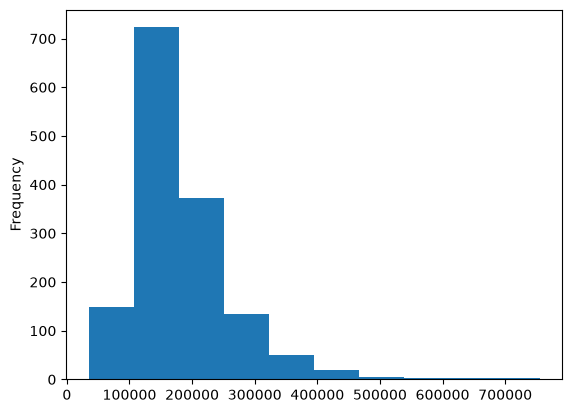

In [5]:
df.SalePrice.plot.hist()

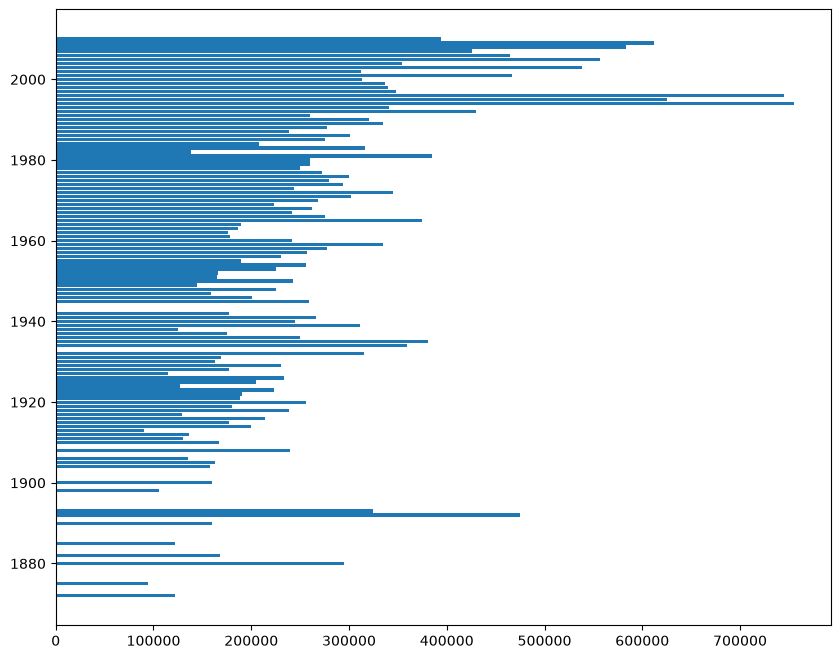

In [6]:
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(df["YearBuilt"], df["SalePrice"]);

In [7]:
df.isna().sum()

Id                 0
MSSubClass         0
MSZoning           0
LotFrontage      259
LotArea            0
                ... 
MoSold             0
YrSold             0
SaleType           0
SaleCondition      0
SalePrice          0
Length: 81, dtype: int64

* Convert String into Categorical

* Fill missing value
> Fill numerical column with median

> Turn categorical values into numbers and fill missing with +1


| Tool                | Job                                                  |
| ------------------- | ---------------------------------------------------- |
| `SimpleImputer`     | Fills missing values                                 |
| `OneHotEncoder`     | Converts categories into numbers                     |
| `ColumnTransformer` | Applies different preprocessing to different columns |
| `Pipeline`          | Connects preprocessing + model into one workflow     |


In [8]:
# pip install xgboost lightgbm

In [9]:
numeric = df.select_dtypes(include=["number"]).columns
numeric

Index(['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual',
       'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1',
       'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd',
       'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF',
       'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea',
       'MiscVal', 'MoSold', 'YrSold', 'SalePrice'],
      dtype='str')

In [10]:
# Find columns where NA means "None" (a real category), not missing data
NONE_COLS = [
    "PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
    "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
    "MasVnrType",
]

# Find columns that are numeric-coded but are actually categorical
FALSE_NUMERIC_COLS = ["MSSubClass"]

# Quality columns with genuine ordering: Ex > Gd > TA > Fa > Po > None
QUAL_MAP = {"Ex": 5, "Gd": 4, "TA": 3, "Fa": 2, "Po": 1, "None": 0}
QUAL_COLS = [
    "ExterQual", "ExterCond", "BsmtQual", "BsmtCond",
    "HeatingQC", "KitchenQual", "FireplaceQu",
    "GarageQual", "GarageCond", "PoolQC",
]

# Other ordinal columns with their own scales
OTHER_ORDINAL_MAPS = {
    "BsmtExposure": {"Gd": 4, "Av": 3, "Mn": 2, "No": 1, "None": 0},
    "BsmtFinType1": {"GLQ": 6, "ALQ": 5, "BLQ": 4, "Rec": 3, "LwQ": 2, "Unf": 1, "None": 0},
    "BsmtFinType2": {"GLQ": 6, "ALQ": 5, "BLQ": 4, "Rec": 3, "LwQ": 2, "Unf": 1, "None": 0},
    "GarageFinish": {"Fin": 3, "RFn": 2, "Unf": 1, "None": 0},
    "Functional": {"Typ": 7, "Min1": 6, "Min2": 5, "Mod": 4, "Maj1": 3, "Maj2": 2, "Sev": 1, "Sal": 0},
    "CentralAir": {"Y": 1, "N": 0},
    "PavedDrive": {"Y": 2, "P": 1, "N": 0},
}

In [11]:
def clean_data(df):
    """
    Apply all cleaning and feature engineering steps to a dataframe.
    """
    df = df.copy()
 
    # NA means "None" for these categorical columns
    for col in NONE_COLS:
        if col in df.columns:
            df[col] = df[col].fillna("None")
 
    # Numeric-coded categoricals
    for col in FALSE_NUMERIC_COLS:
        if col in df.columns:
            df[col] = df[col].astype(str)
 
    # Ordinal encoding: quality scales
    for col in QUAL_COLS:
        if col in df.columns:
            df[col] = df[col].map(QUAL_MAP).fillna(0).astype(int)
 
    # Ordinal encoding: other ordered columns
    for col, mapping in OTHER_ORDINAL_MAPS.items():
        if col in df.columns:
            df[col] = df[col].map(mapping).fillna(0).astype(int)
    return df


df = clean_data(df)
df_test = clean_data(df_test)

In [12]:
# Split into X $ y
X = df.drop(columns=["SalePrice", "Id"])
y_log = np.log1p(df["SalePrice"]) # We use y_log because that is what kaggle wants

test_ids = df_test["Id"]
X_test = df_test.drop(columns=["Id"])

# Split into Training and Validation sets
X_train, X_valid, y_train_log, y_valid_log = train_test_split(X, y_log, test_size=0.2, random_state=42)

## Modelling

### This is the baseline Prediction

In [13]:
# Preprocessing pipelines
# Identify column types
numeric_features = X_train.select_dtypes(include=["number"]).columns
categorical_features = X_train.select_dtypes(include=["object", "category", "str"]).columns

# Use imputer to fill missing numerical column
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
])

# imputer to fill categorical columns and oneHotEncoder to convert categorical to numbers
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

# Transformer to map preprocess to numerical and categorical columns
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features),
])

# Instantiate the models
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(),
    "Lasso": Lasso(),
    "KNN": KNeighborsRegressor(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Extra Trees": ExtraTreesRegressor(random_state=42),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(random_state=42),
    "XGBoost": XGBRegressor(random_state=42),
    "LightGBM": LGBMRegressor(random_state=42),
}

# Compare models with cross-validation (more reliable on small data)
results = {}

for name, model in models.items():
    start = time.time()

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model),
    ])

    cv_scores = cross_val_score(
        pipeline, X_train, y_train_log, cv=5, scoring="neg_root_mean_squared_error"
    )
    rmse_scores = -cv_scores

    # Also fit once on the train split for a quick validation-set check
    pipeline.fit(X_train, y_train_log)
    valid_preds_log = pipeline.predict(X_valid)

    elapsed = time.time() - start

    results[name] = {
        "CV RMSE (log)": rmse_scores.mean(),
        "CV RMSE std": rmse_scores.std(),
        "Valid R2": r2_score(y_valid_log, valid_preds_log),
        "Valid MAE (log)": mean_absolute_error(y_valid_log, valid_preds_log),
        # "Time (s)": round(elapsed, 2),
    }

    print(
        f"{name}: CV RMSE(log)={rmse_scores.mean():.4f} (+/- {rmse_scores.std():.4f}), "
        f"Valid R2={results[name]['Valid R2']:.4f}, Time={elapsed:.2f}s"
    )

results_df = pd.DataFrame(results).T.sort_values("CV RMSE (log)")
print("\nModel comparison (best first):")
print(results_df)

# Pick the best model, retrain on FULL training data, predict on Kaggle test
best_model_name = results_df.index[0]
print(f"\nBest model: {best_model_name}")

best_model = models[best_model_name]

final_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", best_model),
])

# Retrain on ALL available training data (not just the 80% split)
final_pipeline.fit(X, y_log)

# Predict on the real Kaggle test set, then reverse the log transform
test_preds_log = final_pipeline.predict(X_test)
test_preds = np.expm1(test_preds_log)

# ---------------------------------------------------------------------------
# 12. Build submission file
# ---------------------------------------------------------------------------
# submission = pd.DataFrame({
#     ID_COL: test_ids,
#     TARGET: test_preds,
# })
# submission.to_csv("submission.csv", index=False)
# print("\nSaved submission.csv")

Linear Regression: CV RMSE(log)=0.1594 (+/- 0.0341), Valid R2=0.9131, Time=3.98s
Ridge: CV RMSE(log)=0.1480 (+/- 0.0319), Valid R2=0.9135, Time=4.61s
Lasso: CV RMSE(log)=0.1982 (+/- 0.0486), Valid R2=0.8018, Time=6.16s
KNN: CV RMSE(log)=0.2273 (+/- 0.0181), Valid R2=0.7404, Time=22.32s
Decision Tree: CV RMSE(log)=0.2097 (+/- 0.0220), Valid R2=0.8072, Time=10.17s
Random Forest: CV RMSE(log)=0.1435 (+/- 0.0205), Valid R2=0.8862, Time=83.78s
Extra Trees: CV RMSE(log)=0.1449 (+/- 0.0177), Valid R2=0.8869, Time=61.33s
Hist Gradient Boosting: CV RMSE(log)=0.1340 (+/- 0.0161), Valid R2=0.8967, Time=50.76s
XGBoost: CV RMSE(log)=0.1416 (+/- 0.0149), Valid R2=0.8808, Time=13.54s
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003077 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2963
[LightGBM] [Info] Number of data points in the train set: 934,

### Model comparison

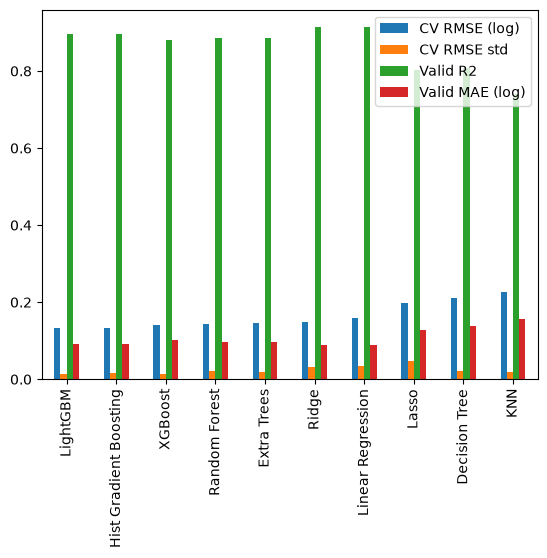

In [14]:
# model_compare = pd.DataFrame(model_scores, index=["accuracy"])
results_df = pd.DataFrame(results).T.sort_values("CV RMSE (log)")
results_df.plot.bar();

## Feature Engineering

In [15]:
# Features Engineering = We are creating and adding extra columns to give additional information
def feature_eng(df):
    df["TotalSF"] = (
        df["TotalBsmtSF"].fillna(0) + df["1stFlrSF"] + df["2ndFlrSF"]
    )
    df["TotalBath"] = (
        df["FullBath"] + 0.5 * df["HalfBath"]
        + df["BsmtFullBath"].fillna(0) + 0.5 * df["BsmtHalfBath"].fillna(0)
    )
    df["Age"] = df["YrSold"] - df["YearBuilt"]
    df["RemodAge"] = df["YrSold"] - df["YearRemodAdd"]
    df["IsRemodeled"] = (df["YearRemodAdd"] != df["YearBuilt"]).astype(int)
    df["TotalPorch"] = (
        df["OpenPorchSF"] + df["EnclosedPorch"] + df["3SsnPorch"]
        + df["ScreenPorch"] + df["WoodDeckSF"]
    )
    df["HasPool"] = (df["PoolArea"] > 0).astype(int)
    df["Has2ndFloor"] = (df["2ndFlrSF"] > 0).astype(int)
    df["HasGarage"] = (df["GarageArea"].fillna(0) > 0).astype(int)
    df["HasBsmt"] = (df["TotalBsmtSF"].fillna(0) > 0).astype(int)
    df["HasFireplace"] = (df["Fireplaces"] > 0).astype(int)
    df["OverallGrade"] = df["OverallQual"] * df["OverallCond"]
    df["ExterGrade"] = df["ExterQual"] * df["ExterCond"]
    df["GarageGrade"] = df["GarageQual"] * df["GarageCond"]
    df["LivAreaPerRoom"] = df["GrLivArea"] / df["TotRmsAbvGrd"].replace(0, np.nan)

    return df

df = feature_eng(df)
df_test = feature_eng(df_test)

## Evaluation
### Hyperparameter tuning

In [16]:
# get the hyperparameter for each model
for name, model in models.items():
    print(f"\n{name}: {model.get_params()}")


Linear Regression: {'copy_X': True, 'fit_intercept': True, 'n_jobs': None, 'positive': False, 'tol': 1e-06}

Ridge: {'alpha': 1.0, 'copy_X': True, 'fit_intercept': True, 'max_iter': None, 'positive': False, 'random_state': None, 'solver': 'auto', 'tol': 0.0001}

Lasso: {'alpha': 1.0, 'copy_X': True, 'fit_intercept': True, 'max_iter': 1000, 'positive': False, 'precompute': False, 'random_state': None, 'selection': 'cyclic', 'tol': 0.0001, 'warm_start': False}

KNN: {'algorithm': 'auto', 'leaf_size': 30, 'metric': 'minkowski', 'metric_params': None, 'n_jobs': None, 'n_neighbors': 5, 'p': 2, 'weights': 'uniform'}

Decision Tree: {'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': None, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 42, 'splitter': 'best'}

Random Forest: {'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_er

### Using RandomizedSearchCV to find the best hyperparamter for the best five model

In [ ]:
from scipy.stats import randint, uniform

# Top 5 models from your comparison
models = {
    "LightGBM": LGBMRegressor(random_state=42),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(random_state=42),
    "XGBoost": XGBRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Extra Trees": ExtraTreesRegressor(random_state=42),
}

# hyperparameters for each model
param_grids = {
    "LightGBM": {
        "model__n_estimators": randint(200, 1500),
        "model__learning_rate": uniform(0.005, 0.15),
        "model__num_leaves": randint(15, 100),
        "model__max_depth": randint(3, 12),
        "model__min_child_samples": randint(5, 50),
        "model__subsample": uniform(0.5, 0.5),
        "model__colsample_bytree": uniform(0.5, 0.5),
        "model__reg_alpha": uniform(0, 1),
        "model__reg_lambda": uniform(0, 1),
    },
    "Hist Gradient Boosting": {
        "model__max_iter": randint(200, 1500),
        "model__learning_rate": uniform(0.005, 0.15),
        "model__max_leaf_nodes": randint(15, 100),
        "model__max_depth": randint(3, 12),
        "model__min_samples_leaf": randint(5, 50),
        "model__l2_regularization": uniform(0, 1),
    },
    "XGBoost": {
        "model__n_estimators": randint(200, 1500),
        "model__learning_rate": uniform(0.005, 0.15),
        "model__max_depth": randint(3, 12),
        "model__min_child_weight": randint(1, 10),
        "model__subsample": uniform(0.5, 0.5),
        "model__colsample_bytree": uniform(0.5, 0.5),
        "model__reg_alpha": uniform(0, 1),
        "model__reg_lambda": uniform(0, 1),
    },
    "Random Forest": {
        "model__n_estimators": randint(100, 1000),
        "model__max_depth": randint(3, 30),
        "model__min_samples_split": randint(2, 20),
        "model__min_samples_leaf": randint(1, 10),
        "model__max_features": uniform(0.3, 0.7),
    },
    "Extra Trees": {
        "model__n_estimators": randint(100, 1000),
        "model__max_depth": randint(3, 30),
        "model__min_samples_split": randint(2, 20),
        "model__min_samples_leaf": randint(1, 10),
        "model__max_features": uniform(0.3, 0.7),
    },
}

# Tuning each model with RandomizedSearchCV (full training data)

tuned_results = {}
best_pipelines = {}

for name, model in models.items():
    # instantiate the preprocessor
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model),
    ])

    # insatantiate the RandomizedSearchCV
    rs_model = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=param_grids[name],
        n_iter=60,
        scoring="neg_root_mean_squared_error",
        cv=10,
        random_state=42,
        n_jobs=-1,
        verbose=0,
    )

    rs_model.fit(X_train, y_train_log)

    tuned_results[name] = -rs_model.best_score_
    best_pipelines[name] = rs_model.best_estimator_

    print(f"{name}: Tuned CV RMSE (log) = {-rs_model.best_score_:.4f}")
    print(f"  Best params: {rs_model.best_params_}\n")

# Summary sorted by best score
tuned_df = pd.Series(tuned_results).sort_values()
print("Tuned model comparison (best first):")
print(tuned_df)

best_overall_name = tuned_df.index[0]
best_overall_pipeline = best_pipelines[best_overall_name]
print(f"\nBest overall tuned model: {best_overall_name}")

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002131 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3142
[LightGBM] [Info] Number of data points in the train set: 1168, number of used features: 143
[LightGBM] [Info] Start training from score 12.030658
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain

In [ ]:
# Check whether any best param landed on a range boundary
def check_boundary_hits(search, param_grid, tolerance=0.05):
    """
    Flags any best_param values sitting within `tolerance` fraction 
    of their search range's edges.
    """
    for param, distribution in param_grid.items():
        best_val = search.best_params_.get(param)
        if best_val is None:
            continue
        
        # Get the range this param was sampled from
        all_vals = [v[param] for v in search.cv_results_["params"] if param in v]
        low, high = min(all_vals), max(all_vals)
        range_span = high - low
        
        if range_span == 0:
            continue
        
        position = (best_val - low) / range_span  # 0 = at low edge, 1 = at high edge
        
        if position <= tolerance or position >= (1 - tolerance):
            edge = "LOW" if position <= tolerance else "HIGH"
            print(f"⚠️  {param}: best={best_val} is near the {edge} edge "
                  f"(range was [{low:.4g}, {high:.4g}]) — consider widening this range")
        else:
            print(f"✓  {param}: best={best_val} is well within range [{low:.4g}, {high:.4g}]")

# check_boundary_hits(search, param_grids["LightGBM"])

In [ ]:
def plot_param_search(search, param_grid, model_name):
    """
    Visualizes where each sampled hyperparameter value landed,
    colored by how well it scored, so you can spot boundary issues.
    """
    results_df = pd.DataFrame(search.cv_results_)
    results_df["mean_test_score"] = -results_df["mean_test_score"]  # flip back to RMSE

    param_names = list(param_grid.keys())
    n_params = len(param_names)
    
    fig, axes = plt.subplots(1, n_params, figsize=(5 * n_params, 4))
    if n_params == 1:
        axes = [axes]

    for ax, param in zip(axes, param_names):
        col = f"param_{param}"
        if col not in results_df.columns:
            continue
        
        x_vals = results_df[col].astype(float)
        y_vals = results_df["mean_test_score"]

        scatter = ax.scatter(x_vals, y_vals, c=y_vals, cmap="viridis_r", alpha=0.7)
        ax.set_xlabel(param.replace("model__", ""))
        ax.set_ylabel("CV RMSE (log)")
        ax.set_title(f"{model_name}: {param.replace('model__', '')}")
        
        # Mark the best value found
        best_val = search.best_params_[param]
        ax.axvline(best_val, color="red", linestyle="--", alpha=0.6, label=f"Best: {best_val:.3f}" if isinstance(best_val, float) else f"Best: {best_val}")
        ax.legend(fontsize=8)

    plt.tight_layout()
    plt.show()

# plot_param_search(search, param_grids["LightGBM"], "LightGBM")

In [ ]:
# Ensemble the top models
# Pull the tuned model objects out of their pipelines so VotingRegressor can sit inside a single shared preprocessor.
top_3 = tuned_df.index[:3]
 
voting = VotingRegressor(estimators=[
    (name.replace(" ", "_").lower(), best_estimators[name].named_steps["model"])
    for name in top_3
] + [("ridge", Ridge(alpha=10))])
 
ensemble_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", voting),
])
 
ensemble_scores = cross_val_score(
    ensemble_pipeline, X_train, y_train_log,
    cv=CV_FOLDS, scoring="neg_root_mean_squared_error", n_jobs=-1,
)
ensemble_rmse = -ensemble_scores.mean()
 
print(f"\nEnsemble CV RMSE (log) = {ensemble_rmse:.4f}")
print(f"Best single model      = {tuned_df.iloc[0]:.4f} ({tuned_df.index[0]})")

# Picking the model and refit it on ALL training data, predict
if ensemble_rmse < tuned_df.iloc[0]:
    final_model = ensemble_pipeline
    final_name = "Ensemble"
else:
    final_model = best_estimators[tuned_df.index[0]]
    final_name = tuned_df.index[0]
 
print(f"\nFinal model: {final_name}")
 
# Refit on the full training set (not just the 80% split)
final_model.fit(X, y_log)
 
test_preds_log = final_model.predict(X_test_kaggle)
test_preds = np.expm1(test_preds_log)   # reverse the log transform